# Used Car Price Prediction — Machine Learning Project



## 1. Import libraries

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the dataset

In [6]:
import zipfile

zip_path = "/content/archive (1).zip"
target_csv = "CAR DETAILS FROM CAR DEKHO.csv"

with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(target_csv) as f:
        df = pd.read_csv(f)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



Columns: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


## 3. Inspect and clean the dataset

In [7]:
print("Dataset information:")
df.info()
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))
print("\nDuplicate rows:", df.duplicated().sum())

# Standardize column names to simplify later code.
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

# Remove accidental index columns, if present.
df = df.loc[:, ~df.columns.str.contains(r"^unnamed")].copy()
df = df.drop_duplicates().copy()

# Map common CarDekho column variants to a standard schema.
rename_map = {
    "car_name": "name",
    "selling_price": "selling_price",
    "kms_driven": "km_driven",
    "fuel_type": "fuel",
    "seller_type": "seller_type",
    "transmission_type": "transmission",
    "owner": "owner",
    "year": "year"
}
df = df.rename(columns={k:v for k,v in rename_map.items() if k in df.columns})

required = ["selling_price"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Target column missing: {missing_required}. Inspect df.columns and update the dataset URL.")

print("Cleaned shape:", df.shape)
display(df.head())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Missing values:


,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0



Duplicate rows: 763
Cleaned shape: (3577, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 4. Exploratory Data Analysis (EDA)

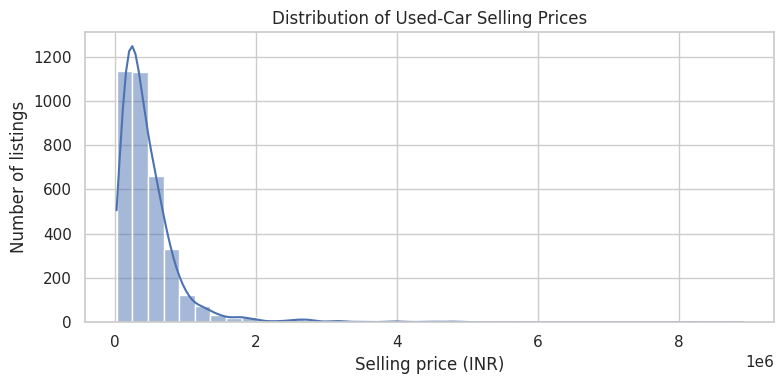

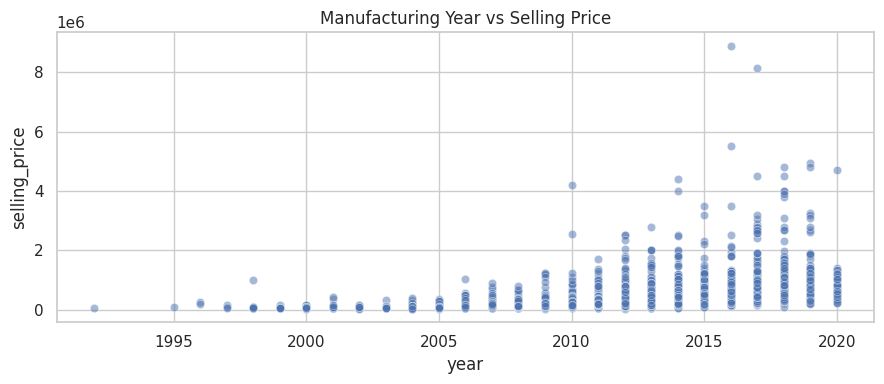

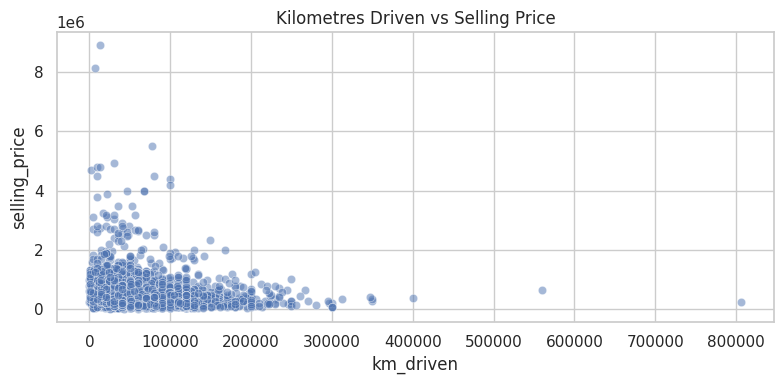

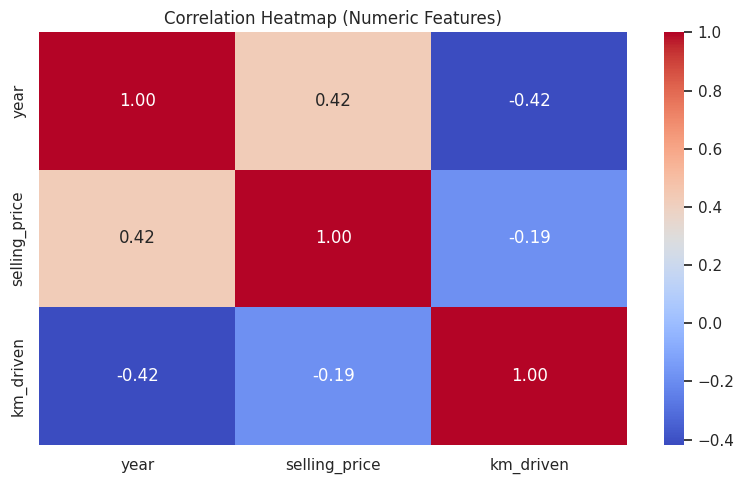

In [8]:
# Target distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["selling_price"], bins=40, kde=True)
plt.title("Distribution of Used-Car Selling Prices")
plt.xlabel("Selling price (INR)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()

# Convert year to numeric if available; plot selling price by manufacturing year.
if "year" in df.columns:
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    plt.figure(figsize=(9, 4))
    sns.scatterplot(data=df, x="year", y="selling_price", alpha=0.5)
    plt.title("Manufacturing Year vs Selling Price")
    plt.tight_layout()
    plt.show()

# Kilometres driven vs price
if "km_driven" in df.columns:
    df["km_driven"] = pd.to_numeric(df["km_driven"], errors="coerce")
    plt.figure(figsize=(8, 4))
    sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.5)
    plt.title("Kilometres Driven vs Selling Price")
    plt.tight_layout()
    plt.show()

# Correlation heatmap for numeric columns
numeric_for_corr = df.select_dtypes(include=np.number)
if numeric_for_corr.shape[1] >= 2:
    plt.figure(figsize=(8, 5))
    sns.heatmap(numeric_for_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap (Numeric Features)")
    plt.tight_layout()
    plt.show()


## 5. Feature engineering and target selection


In [9]:
CURRENT_YEAR = pd.Timestamp.today().year

if "year" in df.columns:
    df["car_age"] = CURRENT_YEAR - df["year"]
    # Remove impossible/future ages and extreme invalid manufacturing years.
    df.loc[(df["car_age"] < 0) | (df["car_age"] > 60), "car_age"] = np.nan

# Ensure target is numeric and valid.
df["selling_price"] = pd.to_numeric(df["selling_price"], errors="coerce")
df = df.dropna(subset=["selling_price"])
df = df[df["selling_price"] > 0].copy()

# Remove columns unlikely to generalize or acting as identifiers.
drop_candidates = ["selling_price", "year", "name", "car_name", "car_name"]
X = df.drop(columns=[c for c in drop_candidates if c in df.columns])
y = df["selling_price"].astype(float)

# Keep only features with at least some non-null data.
X = X.drop(columns=[c for c in X.columns if X[c].isna().all()])

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

print("Feature count:", X.shape[1])
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Rows available:", len(X))


Feature count: 6
Numerical features: ['km_driven', 'car_age']
Categorical features: ['fuel', 'seller_type', 'transmission', 'owner']
Rows available: 3577


## 6. Split data and build preprocessing pipeline


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")


Training rows: 2861
Testing rows: 716


## 7. Train and compare models



In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

trained_models = {}
predictions = {}
rows = []

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred
    rows.append({
        "Model": model_name,
        "MAE (INR)": mean_absolute_error(y_test, y_pred),
        "RMSE (INR)": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(rows).sort_values("RMSE (INR)").reset_index(drop=True)
display(results_df.round(2))
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
print("Best model by test RMSE:", best_model_name)


,Model,MAE (INR),RMSE (INR),R2
0,Gradient Boosting,180010.55,415248.25,0.46
1,Random Forest,192032.62,422695.97,0.45
2,Linear Regression,213179.07,442437.12,0.39


Best model by test RMSE: Gradient Boosting


## 8. Visualize model performance

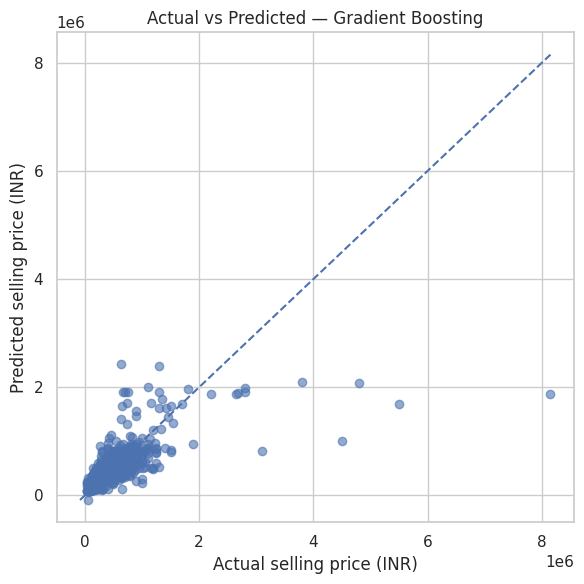

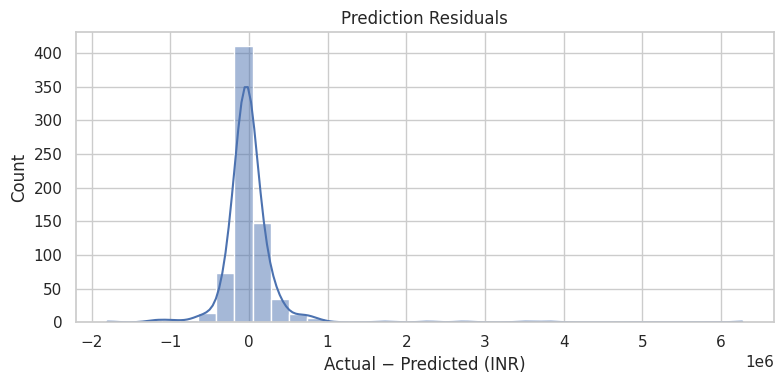

,Actual price (INR),Predicted price (INR),Absolute error (INR)
0,270000.0,486037.0,216037.0
1,525000.0,444777.0,80223.0
2,990000.0,724218.0,265782.0
3,3800000.0,2099807.0,1700193.0
4,229999.0,116149.0,113850.0
5,325000.0,268135.0,56865.0
6,210000.0,129639.0,80361.0
7,500000.0,710085.0,210085.0
8,790000.0,912299.0,122299.0
9,360000.0,328912.0,31088.0


In [12]:
best_pred = predictions[best_model_name]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.6)
low = min(y_test.min(), best_pred.min())
high = max(y_test.max(), best_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual selling price (INR)")
plt.ylabel("Predicted selling price (INR)")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

residuals = y_test - best_pred
plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=35, kde=True)
plt.title("Prediction Residuals")
plt.xlabel("Actual − Predicted (INR)")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Actual price (INR)": y_test.values,
    "Predicted price (INR)": np.round(best_pred, 0),
    "Absolute error (INR)": np.round(np.abs(y_test.values - best_pred), 0)
})
display(comparison.head(10))


## 9. Feature importance (tree-based model)


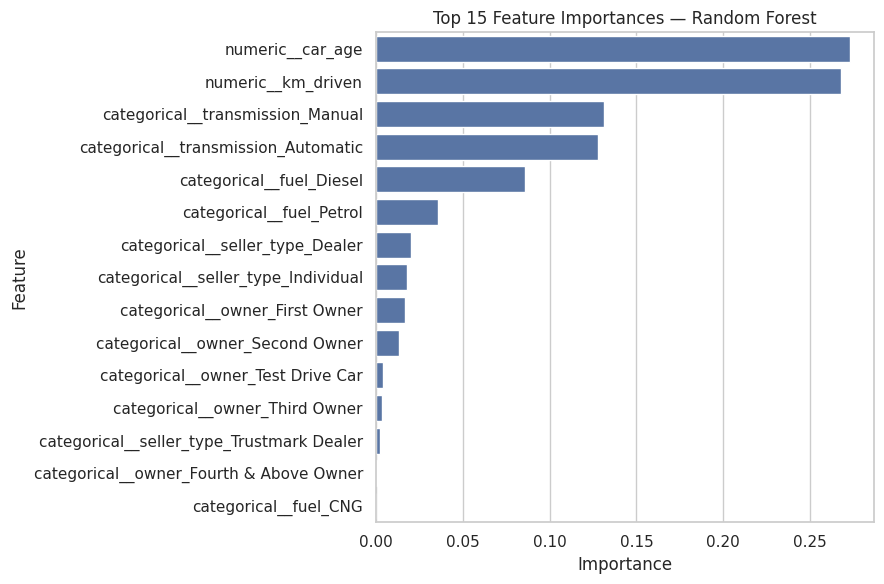

,Feature,Importance
1,numeric__car_age,0.273290
0,numeric__km_driven,0.267878
10,categorical__transmission_Manual,0.131374
9,categorical__transmission_Automatic,0.127997
3,categorical__fuel_Diesel,0.085597
5,categorical__fuel_Petrol,0.035511
6,categorical__seller_type_Dealer,0.019854
7,categorical__seller_type_Individual,0.018060
11,categorical__owner_First Owner,0.016767
13,categorical__owner_Second Owner,0.013332


In [13]:
importance_pipeline = trained_models.get("Random Forest")
if importance_pipeline is not None:
    fitted_preprocessor = importance_pipeline.named_steps["preprocessor"]
    fitted_model = importance_pipeline.named_steps["model"]
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_model.feature_importances_
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(15)

    plt.figure(figsize=(9, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title("Top 15 Feature Importances — Random Forest")
    plt.tight_layout()
    plt.show()
    display(importance_df)
else:
    print("Random Forest model not available.")


## 10. Predict a used-car price from an example


In [14]:
example_car = X_test.iloc[[0]].copy()
predicted_price = best_model.predict(example_car)[0]

print("Example car features:")
display(example_car)
print(f"Estimated selling price: ₹{predicted_price:,.0f}")
print(f"Actual selling price:    ₹{y_test.iloc[0]:,.0f}")


Example car features:


,km_driven,fuel,seller_type,transmission,owner,car_age
1045,20000,Petrol,Individual,Manual,First Owner,8.0


Estimated selling price: ₹486,037
Actual selling price:    ₹270,000


## 11. Save the trained model


In [15]:
import joblib
MODEL_FILE = "used_car_price_model.joblib"
joblib.dump(best_model, MODEL_FILE)
print(f"Saved model to {MODEL_FILE}")

# In Google Colab, this prompts a browser download.
try:
    from google.colab import files
    files.download(MODEL_FILE)
except ImportError:
    print("Not running in Colab; model file is saved in the current working directory.")


Saved model to used_car_price_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>